#AI-Powered Customer Churn Intelligence System



##Step 1: Load & Understand the Data
###Step 1.1 — Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

###Step 1.2 — Load the Dataset

In [ ]:
df = pd.read_csv("Telco-Customer-Churn.csv")

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


###Step 1.3 — Check Dataset Shape

In [ ]:
df.shape                 #7,043 rows → customers
                         #21 columns → customer attributes

(7043, 21)

###Step 1.4 — Check Column Names

In [ ]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

###Step 1.5 — Check Data Types

In [ ]:
df.dtypes

,0
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


>Checked the data types of all variables and identified TotalCharges as an object column that will require conversion during the cleaning stage.

###Step 1.6 — Basic Dataset Information

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


>Used info() to review the overall structure of the dataset and identify columns with missing or inconsistent data types.

###Step 1.7 — Check Numerical Summary

In [ ]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


>Generated descriptive statistics to understand the distribution and range of the numerical customer attributes.

###Step 1.8 — Check the Target Variable

Our target variable is Churn.

In [ ]:
df["Churn"].value_counts()

,count
Churn,
No,5174
Yes,1869


In [ ]:
df["Churn"].value_counts(normalize=True) * 100

,proportion
Churn,
No,73.463013
Yes,26.536987


>Examined the distribution of the target variable Churn to understand the proportion of customers who stayed versus those who left.

##Step 2: Data Cleaning

###Step 2.1 — Check Missing Values

In [ ]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


>Checked all columns for missing values to identify fields that require cleaning before analysis and modeling.

###Step 2.2 — Check Duplicate Records

In [ ]:
df.duplicated().sum()

np.int64(0)

>Checked for duplicate customer records to ensure that each observation represents a unique customer entry.

###Step 2.3 — Convert TotalCharges to Numeric

We already know from SQL that TotalCharges contains 11 blank values. Pandas currently sees this column as object.

We'll convert it using pd.to_numeric().

In [ ]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

                                                                             #errors="coerce" converts values that cannot be interpreted as numbers into NaN.

>Converted TotalCharges from object to numeric format, with invalid or blank values converted to missing values (NaN).

###Step 2.4 — Check TotalCharges Again

In [ ]:
df["TotalCharges"].isnull().sum()                #These are the same 11 blank records we identified in SQL.

np.int64(11)

>After conversion, 11 missing values were identified in TotalCharges, corresponding to the blank billing records in the original dataset.

###Step 2.5 - Investigate the Missing Records

In [ ]:
df[df["TotalCharges"].isnull()][
    ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


>Investigated the missing TotalCharges records and found that they correspond to customers with zero months of tenure.
> Their TotalCharges is missing because they are essentially new customers with no accumulated charges yet.

###Step 2.6 — Handle Missing TotalCharges

Since these customers have tenure = 0, we can reasonably treat their accumulated charges as $0.


In [ ]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

>Replaced missing TotalCharges values with 0 because these records represent new customers with zero tenure and no accumulated charges.

###Step 2.7 — Verify Missing Values Again

In [ ]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


>Rechecked the dataset after cleaning and confirmed that there are no remaining missing values.

###Step 2.8 — Verify Data Types

In [ ]:
df.dtypes

,0
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


>Verified the cleaned data types and confirmed that TotalCharges is now stored as a numeric variable suitable for analysis and machine learning.

##Step 3: EDA (Exploratory Data Analysis)

###EDA 3.1 - Overall Churn Distribution
>What percentage of customers have churned?

In [ ]:
churn_counts = df["Churn"].value_counts()

churn_counts

,count
Churn,
No,5174
Yes,1869


>Calculated the number of customers who stayed and churned to understand the overall distribution of the target variable.

In [ ]:
churn_percentage = df["Churn"].value_counts(normalize=True) * 100

churn_percentage.round(2)

,proportion
Churn,
No,73.46
Yes,26.54


>Calculated the percentage distribution of churn to measure the overall customer churn rate.

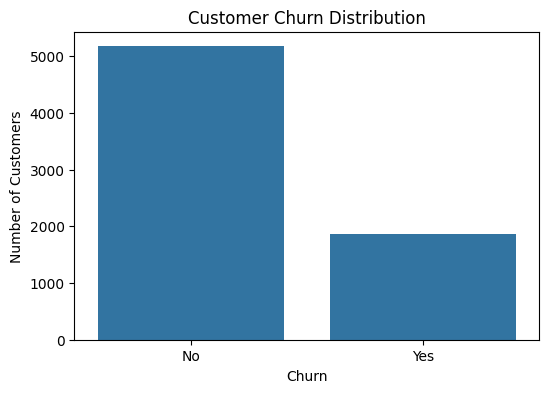

In [ ]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

>Visualized the churn distribution to compare the number of customers who stayed with those who churned.

>You should see approximately:   
>* No: 73.5%
>* Yes: 26.5%

>So our dataset has roughly a 26.5% churn rate.

>This gives us our baseline churn rate. Every segment we analyze next can be compared against this 26.5%

###EDA 3.2 - Churn by Contract Type


Which contract type has the highest churn?

In [ ]:
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

contract_churn.round(2)

Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


>Calculated the percentage of churned and retained customers within each contract type to identify contracts associated with higher churn.

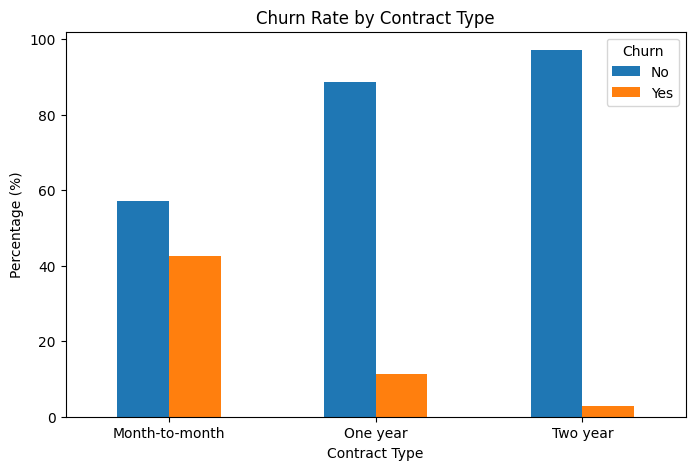

In [ ]:
contract_churn.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)

plt.show()

>Visualized churn rates across contract types to identify which contract structure has the highest customer churn.

###EDA 3.3 — Churn by Tenure

Are newer customers more likely to churn?

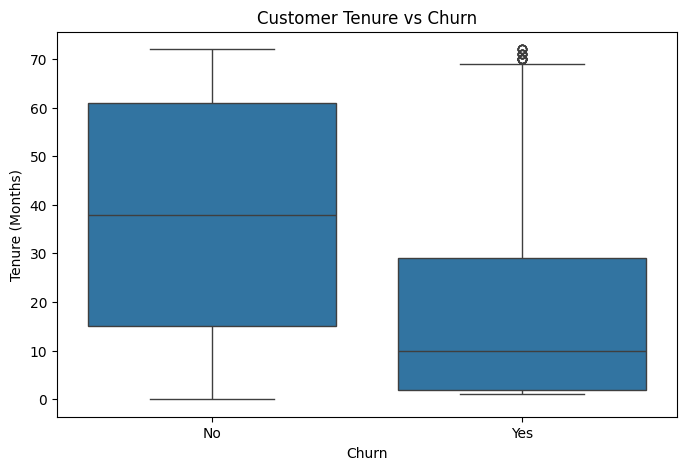

In [ ]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure"
)

plt.title("Customer Tenure vs Churn")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")

plt.show()

>Compared customer tenure between churned and retained customers to identify whether customers with shorter relationships are more likely to churn.

###EDA 3.4 - Churn vs Monthly Charges

Are customers with higher monthly charges more likely to churn?

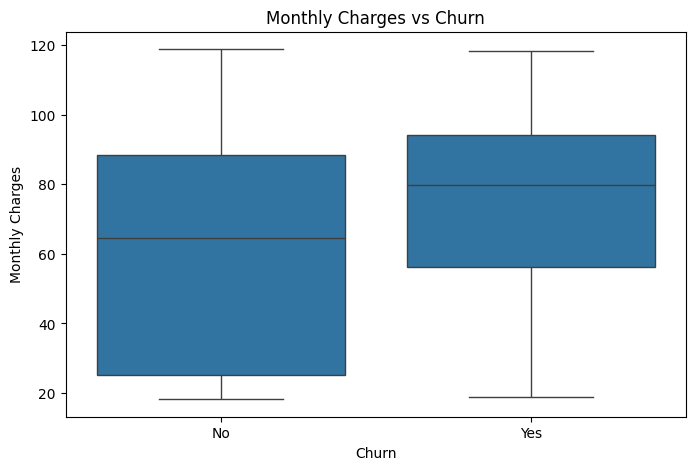

In [ ]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges vs Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.show()

>Compared monthly charges between churned and retained customers to determine whether higher monthly costs are associated with churn.

###EDA 3.5 — Churn by Payment Method

Which payment methods are associated with higher churn?


In [ ]:
payment_churn = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

payment_churn.round(2)

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.29,16.71
Credit card (automatic),84.76,15.24
Electronic check,54.71,45.29
Mailed check,80.89,19.11


>Calculated churn rates for each payment method to identify payment groups with unusually high customer churn.

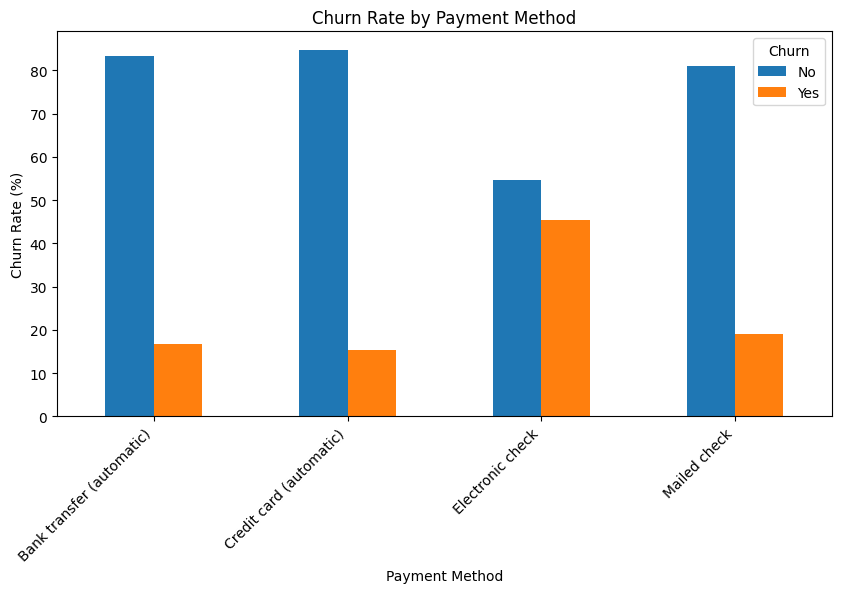

In [ ]:
payment_churn.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=45, ha="right")

plt.show()

>Visualized churn rates by payment method to make differences between customer payment groups easier to identify.

###EDA 3.6 — Churn by Internet Service

Does the type of internet service affect churn?

In [ ]:
internet_churn = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

internet_churn.round(2)

Churn,No,Yes
InternetService,,
DSL,81.04,18.96
Fiber optic,58.11,41.89
No,92.60,7.40


>Calculated the churn rate for each internet service category to determine whether service type is associated with customer churn.

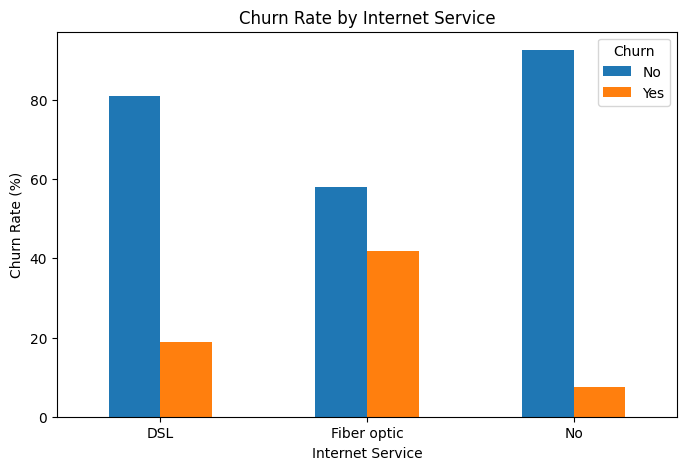

In [ ]:
internet_churn.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Churn Rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)

plt.show()

>Visualized churn rates across internet service categories to identify services associated with higher customer attrition.

###EDA 3.7 - Churn by Senior Citizen Status

Does customer age group influence churn?

The dataset represents SeniorCitizen as:

* 0 = Not Senior Citizen
* 1 = Senior Citizen

In [ ]:
senior_churn = pd.crosstab(
    df["SeniorCitizen"],
    df["Churn"],
    normalize="index"
) * 100

senior_churn.round(2)

Churn,No,Yes
SeniorCitizen,,
0,76.39,23.61
1,58.32,41.68


>Calculated churn rates for senior and non-senior customers to examine whether customer age group is associated with churn.

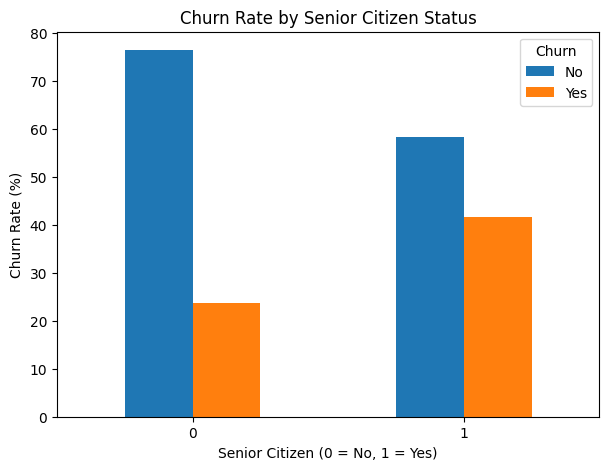

In [ ]:
senior_churn.plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Churn Rate by Senior Citizen Status")
plt.xlabel("Senior Citizen (0 = No, 1 = Yes)")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)

plt.show()

>Visualized churn rates by senior citizen status to compare customer retention patterns across age groups.

###EDA 3.8 — Churn by Additional Services

The Telco dataset has several service-related columns:

OnlineSecurity
OnlineBackup
DeviceProtection
TechSupport
StreamingTV
StreamingMovies

Rather than making six repetitive charts, we'll analyze them together.

>Does subscribing to additional services relate to customer churn?

In [ ]:
service_columns = [
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]

service_churn = {}

for service in service_columns:
    service_churn[service] = (
        df.groupby(service)["Churn"]
        .apply(lambda x: (x == "Yes").mean() * 100)
    )

service_churn_df = pd.DataFrame(service_churn)

service_churn_df.round(2)

,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies
No,41.77,39.93,39.13,41.64,33.52,33.68
No internet service,7.40,7.40,7.40,7.40,7.40,7.40
Yes,14.61,21.53,22.50,15.17,30.07,29.94


>Calculated churn rates across multiple additional services to identify whether service subscriptions are associated with customer retention.

##Step 4 — Feature Engineering

Before we train a model, we need to convert our customer data into a format that machine-learning algorithms can understand.

###4.1 Select Features & Target

Separate:

X → customer information used for prediction
y → Churn, our target

In [ ]:
X = df.drop(columns=["customerID", "Churn"])
y = df["Churn"]

In [ ]:
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (7043, 19)
Target shape: (7043,)


>Separated the dataset into predictor variables (X) and the target variable (y). customerID was excluded because it is an identifier and does not contribute meaningful predictive information.

###4.2 — Identify Numerical and Categorical Features

In [ ]:
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


>Identified numerical and categorical variables so that each type can receive the appropriate preprocessing before model training.

###4.3 — Convert Target Variable

Our target currently contains:

* No
* Yes

Machine-learning models need numerical labels, so we'll convert:

- No  → 0
- Yes → 1

In [ ]:
y = y.map({"No": 0, "Yes": 1})

y.value_counts()

,count
Churn,
0,5174
1,1869


>Converted the churn target into binary numerical labels, where 0 represents retained customers and 1 represents churned customers.**bold text**

###4.4 — Train-Test Split

We'll use 80% for training and 20% for testing.

We'll also use stratify=y so that the churn proportion remains similar in both datasets.

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (5634, 19)
X_test: (1409, 19)
y_train: (5634,)
y_test: (1409,)


>Split the data into 80% training and 20% testing sets, using stratification to preserve the original churn distribution in both datasets.

###4.5 — Create Preprocessing Pipeline

Now we'll build the actual preprocessing system.

For numerical features:

We'll use StandardScaler.

For categorical features:

We'll use OneHotEncoder.

In [ ]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [ ]:
##Now create the preprocessing transformer:
numeric_transformer = Pipeline(
    steps=[
        ("scaler", StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]
)

In [ ]:
##Then combine them:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

>Created a preprocessing pipeline that standardizes numerical features and one-hot encodes categorical features while keeping preprocessing consistent between training and testing data.

###4.6 — Fit the Preprocessor on Training Data

Now we'll apply the preprocessing.

Important: We fit the preprocessing only on training data to avoid data leakage.

In [ ]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed X_train shape:", X_train_processed.shape)
print("Processed X_test shape:", X_test_processed.shape)

Processed X_train shape: (5634, 45)
Processed X_test shape: (1409, 45)


>Applied the preprocessing pipeline to transform the training and testing datasets into numerical ML-ready features while preventing data leakage.

###4.7 — Verify the Final Data
Let's check whether the processed data contains missing values.

In [ ]:
import numpy as np

print("Missing values in X_train:",
      np.isnan(X_train_processed).sum())

print("Missing values in X_test:",
      np.isnan(X_test_processed).sum())

Missing values in X_train: 0
Missing values in X_test: 0


> Verified the processed datasets and confirmed that the feature matrix contains no missing numerical values.

###4.8 — Check Target Distribution

Finally, let's make sure the train/test split maintained the churn distribution.

In [ ]:
print("Training churn rate:")
print(y_train.mean() * 100)

print("\nTesting churn rate:")
print(y_test.mean() * 100)

print("\nOverall churn rate:")
print(y.mean() * 100)

Training churn rate:
26.53532126375577

Testing churn rate:
26.54364797728886

Overall churn rate:
26.536987079369588


>Verified that the churn distribution remains consistent across the overall, training, and testing datasets after stratified splitting.

##Step 5: Machine Learning

###5.1 — Import Machine Learning Libraries

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

###5.2 — Train Logistic Regression

In [ ]:
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train_processed, y_train)

LogisticRegression(max_iter=1000, random_state=42)

>Trained a Logistic Regression model as the baseline classifier for predicting customer churn.

###5.3 — Train Random Forest

In [ ]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

rf_model.fit(X_train_processed, y_train)

RandomForestClassifier(class_weight='balanced', n_estimators=200,
                       random_state=42)

>Trained a Random Forest classifier to capture nonlinear relationships and improve churn prediction performance.

###5.4 — Train XGBoost

In [ ]:
xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    random_state=42
)

xgb_model.fit(X_train_processed, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=4, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=200, n_jobs=None,
              num_parallel_tree=None, ...)

>Trained an XGBoost classifier to model complex relationships in customer data and provide a strong candidate for the final churn prediction model.

###5.5 — Generate Predictions

In [ ]:
models = {
    "Logistic Regression": logistic_model,
    "Random Forest": rf_model,
    "XGBoost": xgb_model
}

results = []

for name, model in models.items():

    y_pred = model.predict(X_test_processed)
    y_prob = model.predict_proba(X_test_processed)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)

results_df.round(4)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.8055,0.6572,0.5588,0.6040,0.8421
1,Random Forest,0.7828,0.6189,0.4733,0.5364,0.8232
2,XGBoost,0.8055,0.6724,0.5214,0.5873,0.8452


>Evaluated all three models using accuracy, precision, recall, F1-score, and ROC-AUC to compare their churn prediction performance.

###5.6 — Visualize Model Comparison

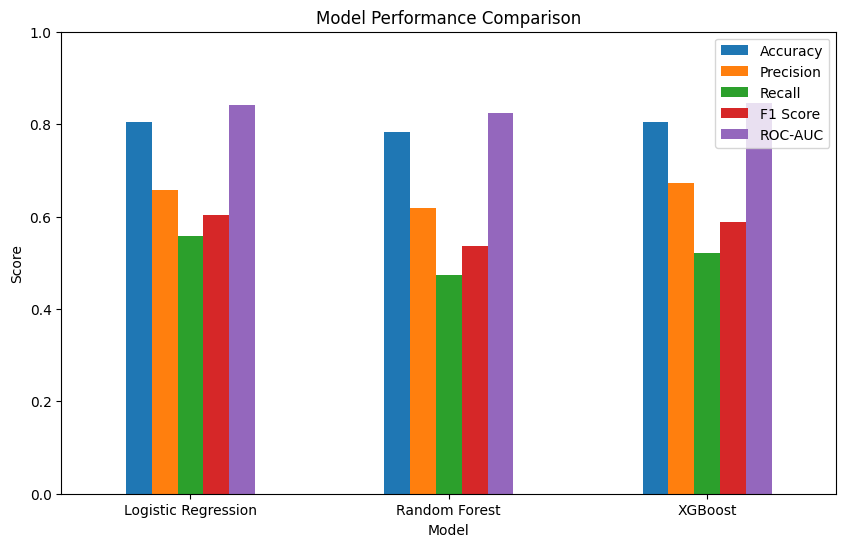

In [ ]:
results_plot = results_df.set_index("Model")

results_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.ylim(0, 1)

plt.show()

>Compared model performance visually across multiple evaluation metrics to identify the strongest candidate for churn prediction.

###5.7 — Detailed Classification Report

In [ ]:
for name, model in models.items():

    y_pred = model.predict(X_test_processed)

    print("=" * 60)
    print(name)
    print("=" * 60)

    print(classification_report(
        y_test,
        y_pred,
        target_names=["No Churn", "Churn"]
    ))

Logistic Regression
              precision    recall  f1-score   support

    No Churn       0.85      0.89      0.87      1035
       Churn       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409

Random Forest
              precision    recall  f1-score   support

    No Churn       0.82      0.89      0.86      1035
       Churn       0.62      0.47      0.54       374

    accuracy                           0.78      1409
   macro avg       0.72      0.68      0.70      1409
weighted avg       0.77      0.78      0.77      1409

XGBoost
              precision    recall  f1-score   support

    No Churn       0.84      0.91      0.87      1035
       Churn       0.67      0.52      0.59       374

    accuracy                           0.81      1409
   macro avg       0.76      0.71      0.73      1409
weighted avg       0.80      0.8

>Generated detailed classification reports to examine precision, recall, and F1-score separately for churned and retained customers.

###5.8 — Confusion Matrix for the Best Model

In [ ]:
best_model_name = results_df.loc[
    results_df["ROC-AUC"].idxmax(),
    "Model"
]

print("Best Model:", best_model_name)

Best Model: XGBoost


>Selected the model with the highest ROC-AUC as the initial best-performing model for distinguishing churned customers from retained customers.

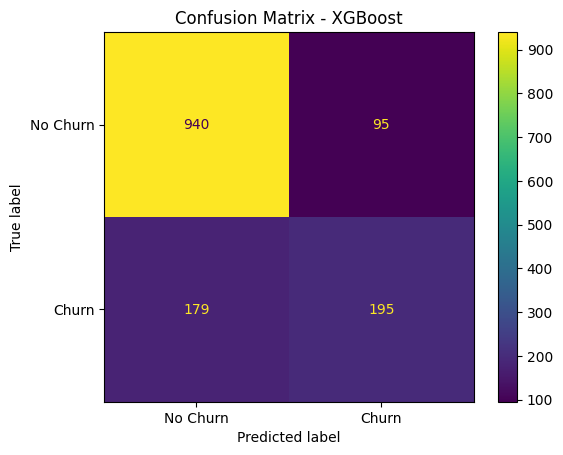

In [ ]:
best_model = models[best_model_name]

best_predictions = best_model.predict(X_test_processed)

cm = confusion_matrix(y_test, best_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
)

disp.plot()

plt.title(f"Confusion Matrix - {best_model_name}")
plt.show()

>XGBoost was selected as the primary model based on its highest ROC-AUC and precision, while Logistic Regression provided slightly higher recall and F1-score.

>Compared three classification models and selected XGBoost as the primary model based on its highest ROC-AUC (0.8452) and precision (0.6724), while considering the trade-off with Logistic Regression's higher recall.

##Step 6 - Customer Churn Prediction

###Step 6.1 - Generate Churn Probability

In [ ]:
y_test_probability = best_model.predict_proba(X_test_processed)[:, 1]

y_test_probability[:10]

array([0.0144771 , 0.8687383 , 0.06655761, 0.37816286, 0.00885646,
       0.6292069 , 0.45367703, 0.09763297, 0.0184017 , 0.35557455],
      dtype=float32)

>Generated individual customer churn probabilities using the selected XGBoost model to measure each customer's likelihood of churning.

###Step 6.2 — Create Customer Prediction Dataset

X_test contains the original customer features, and y_test contains the actual churn outcome.

In [ ]:
prediction_df = X_test.copy()

prediction_df["Actual_Churn"] = y_test
prediction_df["Churn_Probability"] = y_test_probability

prediction_df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Actual_Churn,Churn_Probability
437,Male,0,Yes,Yes,72,Yes,Yes,Fiber optic,Yes,Yes,...,Yes,Yes,Yes,Two year,Yes,Credit card (automatic),114.05,8468.20,0,0.014477
2280,Female,1,No,No,8,Yes,Yes,Fiber optic,No,No,...,Yes,Yes,Yes,Month-to-month,Yes,Credit card (automatic),100.15,908.55,0,0.868738
2235,Female,0,Yes,Yes,41,Yes,Yes,DSL,Yes,Yes,...,No,Yes,No,One year,Yes,Credit card (automatic),78.35,3211.20,0,0.066558
4460,Male,0,Yes,No,18,Yes,No,Fiber optic,No,No,...,Yes,No,No,Month-to-month,No,Electronic check,78.20,1468.75,0,0.378163
3761,Female,0,Yes,No,72,Yes,Yes,DSL,Yes,Yes,...,No,Yes,Yes,Two year,Yes,Credit card (automatic),82.65,5919.35,0,0.008856


>Created a prediction dataset containing customer features, actual churn status, and the model-generated churn probability.

###Step 6.3 — Add Customer ID

In [ ]:
prediction_df["customerID"] = df.loc[
    prediction_df.index,
    "customerID"
]

In [ ]:
cols = prediction_df.columns.tolist()

cols = ["customerID"] + [
    col for col in cols
    if col != "customerID"
]

prediction_df = prediction_df[cols]

prediction_df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Actual_Churn,Churn_Probability
437,4376-KFVRS,Male,0,Yes,Yes,72,Yes,Yes,Fiber optic,Yes,...,Yes,Yes,Yes,Two year,Yes,Credit card (automatic),114.05,8468.20,0,0.014477
2280,2754-SDJRD,Female,1,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,Yes,Yes,Month-to-month,Yes,Credit card (automatic),100.15,908.55,0,0.868738
2235,9917-KWRBE,Female,0,Yes,Yes,41,Yes,Yes,DSL,Yes,...,No,Yes,No,One year,Yes,Credit card (automatic),78.35,3211.20,0,0.066558
4460,0365-GXEZS,Male,0,Yes,No,18,Yes,No,Fiber optic,No,...,Yes,No,No,Month-to-month,No,Electronic check,78.20,1468.75,0,0.378163
3761,9385-NXKDA,Female,0,Yes,No,72,Yes,Yes,DSL,Yes,...,No,Yes,Yes,Two year,Yes,Credit card (automatic),82.65,5919.35,0,0.008856


>Added the customer ID back to the prediction dataset so that model predictions can be linked to individual customers for business actions.

###Step 6.4 — Create Risk Level

In [ ]:
def assign_risk(probability):
    if probability < 0.30:
        return "Low"
    elif probability < 0.60:
        return "Medium"
    else:
        return "High"


prediction_df["Risk_Level"] = prediction_df[
    "Churn_Probability"
].apply(assign_risk)

>Converted churn probabilities into Low, Medium, and High risk categories to make model predictions easier for business teams to interpret and act upon.

###Step 6.5 — Convert Probability to Percentage

In [ ]:
prediction_df["Churn_Probability_Pct"] = (
    prediction_df["Churn_Probability"] * 100
).round(2)

print(prediction_df["Churn_Probability_Pct"])

437      1.450000
2280    86.870003
2235     6.660000
4460    37.820000
3761     0.890000
          ...    
5143     3.730000
4439     0.740000
3857    11.080000
4758     3.330000
5613     0.550000
Name: Churn_Probability_Pct, Length: 1409, dtype: float32


>Converted churn probabilities into percentage values to create a more intuitive customer risk score.

###Step 6.6 — View High-Risk Customers

In [ ]:
high_risk_customers = prediction_df.sort_values(
    "Churn_Probability",
    ascending=False
)

high_risk_customers[
    [
        "customerID",
        "Churn_Probability_Pct",
        "Risk_Level",
        "Actual_Churn"
    ]
].head(10)

,customerID,Churn_Probability_Pct,Risk_Level,Actual_Churn
3380,5178-LMXOP,93.750000,High,1
4585,1069-XAIEM,93.260002,High,1
6866,0295-PPHDO,93.220001,High,1
6623,9248-OJYKK,92.930000,High,1
2464,2609-IAICY,92.430000,High,1
2631,6861-XWTWQ,92.410004,High,1
1073,0655-RBDUG,90.860001,High,1
2194,2514-GINMM,90.620003,High,1
6365,8884-ADFVN,88.800003,High,1
2797,6023-YEBUP,88.779999,High,1


>Ranked customers by predicted churn probability to identify the highest-risk customers for potential retention actions.

###Step 6.7 — Check Risk Distribution

In [ ]:
prediction_df["Risk_Level"].value_counts()

,count
Risk_Level,
Low,872
Medium,338
High,199


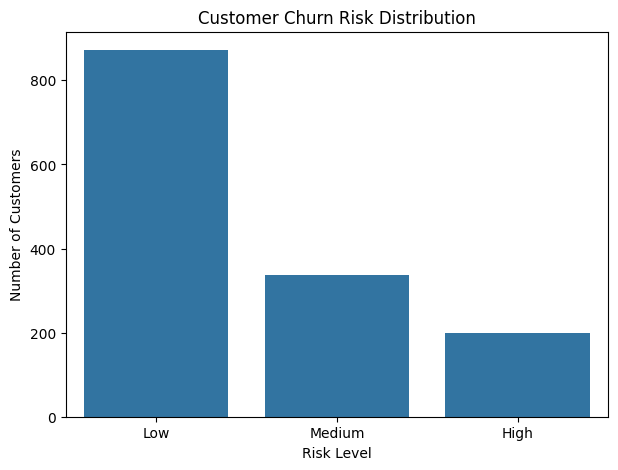

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=prediction_df,
    x="Risk_Level",
    order=["Low", "Medium", "High"]
)

plt.title("Customer Churn Risk Distribution")
plt.xlabel("Risk Level")
plt.ylabel("Number of Customers")

plt.show()

>Examined the distribution of customers across risk levels to understand how many customers require potential retention attention.

###Step 6.8 — Check Whether Risk Level Actually Corresponds to Churn

In [ ]:
risk_validation = prediction_df.groupby(
    "Risk_Level"
)["Actual_Churn"].mean() * 100

risk_validation.round(2)

,Actual_Churn
Risk_Level,
High,71.86
Low,9.86
Medium,42.90


>Validated the risk categories by comparing predicted risk levels with actual churn rates to ensure that higher-risk groups show greater observed churn.

##Step 7 - SHAP Explainability

###Step 7.1 - Install and Import SHAP

In [ ]:
!pip install shap -q

In [ ]:
import shap

###Step 7.2 - Create the SHAP Explainer

In [ ]:
explainer = shap.TreeExplainer(best_model)

###Step 7.3 — Calculate SHAP Values

In [ ]:
shap_values = explainer.shap_values(X_test_processed)

print(shap_values.shape)

(1409, 45)


>Calculated SHAP values for the test dataset to quantify how each feature contributes to the model's churn predictions.

###Step 7.4 — Get the Processed Feature Names

In [ ]:
feature_names = preprocessor.get_feature_names_out()

print("Number of features:", len(feature_names))

Number of features: 45


>Retrieved the feature names generated by the preprocessing pipeline so that SHAP contributions can be mapped back to meaningful customer attributes.

###Step 7.5 — Global Feature Importance

In [ ]:
shap_importance = pd.DataFrame({
    "Feature": feature_names,
    "Mean_Absolute_SHAP": np.abs(shap_values).mean(axis=0)
})

shap_importance = shap_importance.sort_values(
    "Mean_Absolute_SHAP",
    ascending=False
)

shap_importance.head(15)

,Feature,Mean_Absolute_SHAP
36,cat__Contract_Month-to-month,0.645033
1,num__tenure,0.390591
2,num__MonthlyCharges,0.287146
18,cat__OnlineSecurity_No,0.273447
3,num__TotalCharges,0.202092
27,cat__TechSupport_No,0.187555
16,cat__InternetService_Fiber optic,0.174074
43,cat__PaymentMethod_Electronic check,0.168730
38,cat__Contract_Two year,0.162605
39,cat__PaperlessBilling_No,0.112506


>Ranked features by their average absolute SHAP value to identify the most influential factors driving churn predictions across customers.

###Step 7.6 — Visualize Global SHAP Importance

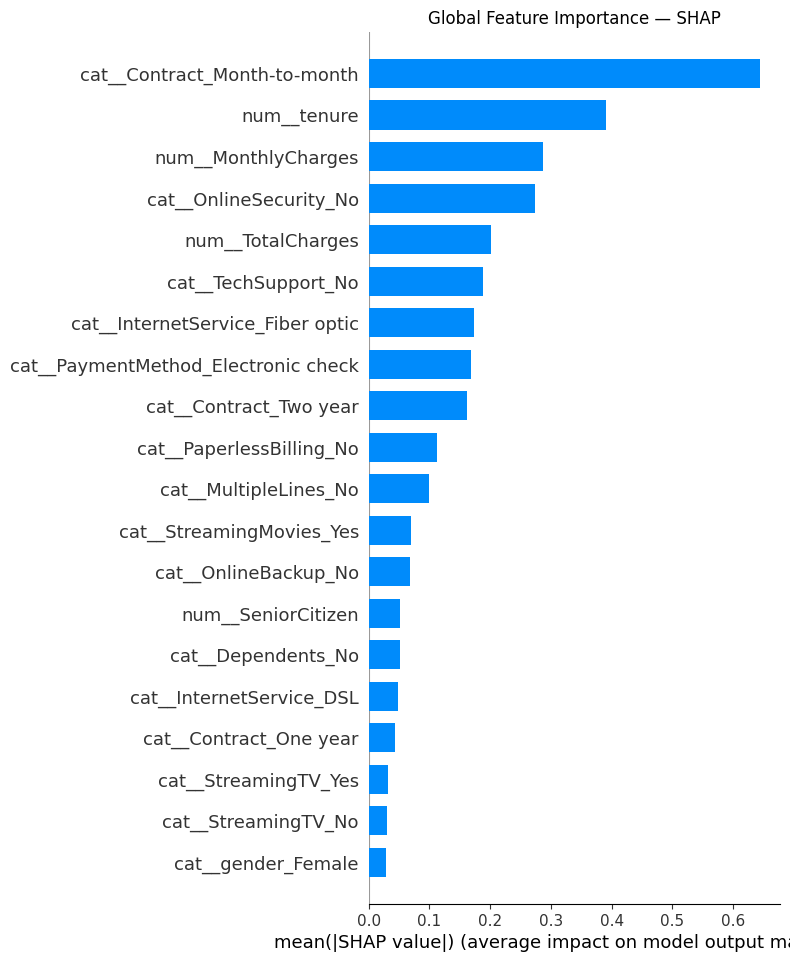

In [ ]:
plt.figure(figsize=(10, 7))

shap.summary_plot(
    shap_values,
    X_test_processed,
    feature_names=feature_names,
    plot_type="bar",
    show=False
)

plt.title("Global Feature Importance — SHAP")
plt.show()

>Visualized global SHAP feature importance to identify the strongest drivers influencing customer churn predictions.

###Step 7.7 — SHAP Summary Plot

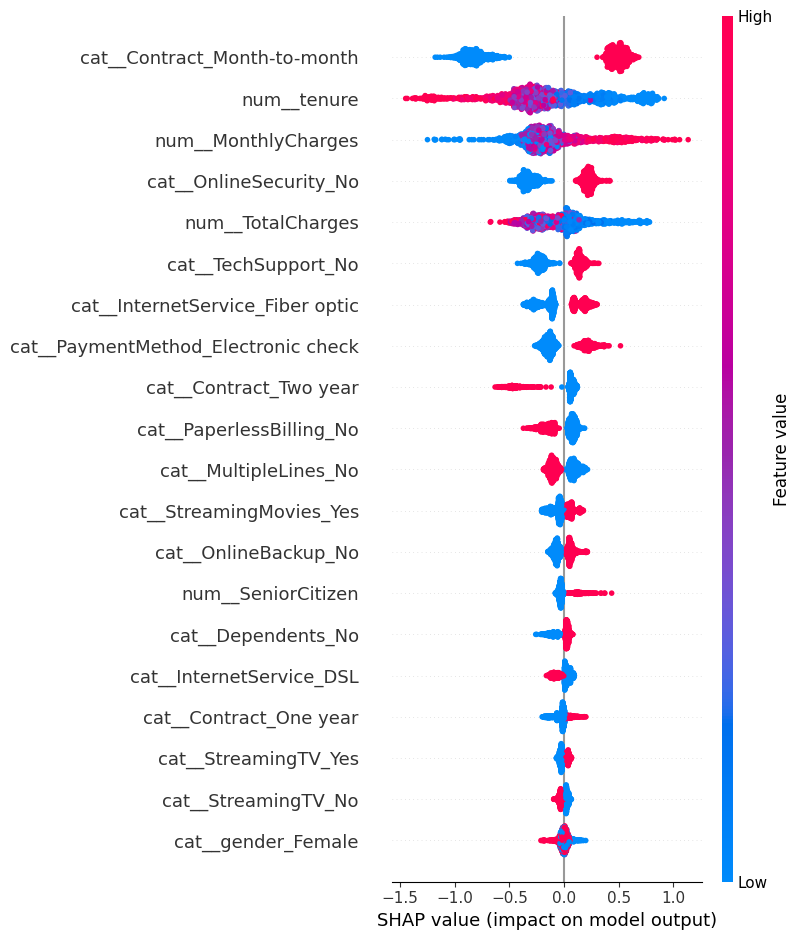

In [ ]:
shap.summary_plot(
    shap_values,
    X_test_processed,
    feature_names=feature_names
)

>Used the SHAP summary plot to understand both the importance and direction of feature effects on individual churn predictions.

###Step 7.8 — Explain One High-Risk Customer

In [ ]:
high_risk_customer = prediction_df.sort_values(
    "Churn_Probability",
    ascending=False
).iloc[0]

high_risk_customer[
    [
        "customerID",
        "Churn_Probability_Pct",
        "Risk_Level",
        "Actual_Churn"
    ]
]

,3380
customerID,5178-LMXOP
Churn_Probability_Pct,93.75
Risk_Level,High
Actual_Churn,1


>Selected the customer with the highest predicted churn probability to demonstrate an individual-level SHAP explanation.

###Step 7.9 — Find That Customer's SHAP Values

In [ ]:
customer_index = high_risk_customer.name

customer_position = X_test.index.get_loc(customer_index)

customer_shap = shap_values[customer_position]

customer_features = X_test_processed[
    customer_position
].flatten()

>Retrieved the selected customer's feature values and corresponding SHAP contributions to explain the individual churn prediction.

###Step 7.10 — Identify the Top Reasons

In [ ]:
customer_explanation = pd.DataFrame({
    "Feature": feature_names,
    "SHAP_Value": customer_shap
})

top_reasons = customer_explanation[
    customer_explanation["SHAP_Value"] > 0
].sort_values(
    "SHAP_Value",
    ascending=False
)

top_reasons.head(5)

,Feature,SHAP_Value
1,num__tenure,0.754844
36,cat__Contract_Month-to-month,0.599006
3,num__TotalCharges,0.503156
18,cat__OnlineSecurity_No,0.211326
2,num__MonthlyCharges,0.208090


>Identified the features with the strongest positive SHAP contributions as the primary reasons increasing this customer's predicted churn risk.

###Step 7.11 — Visualize the Individual Explanation

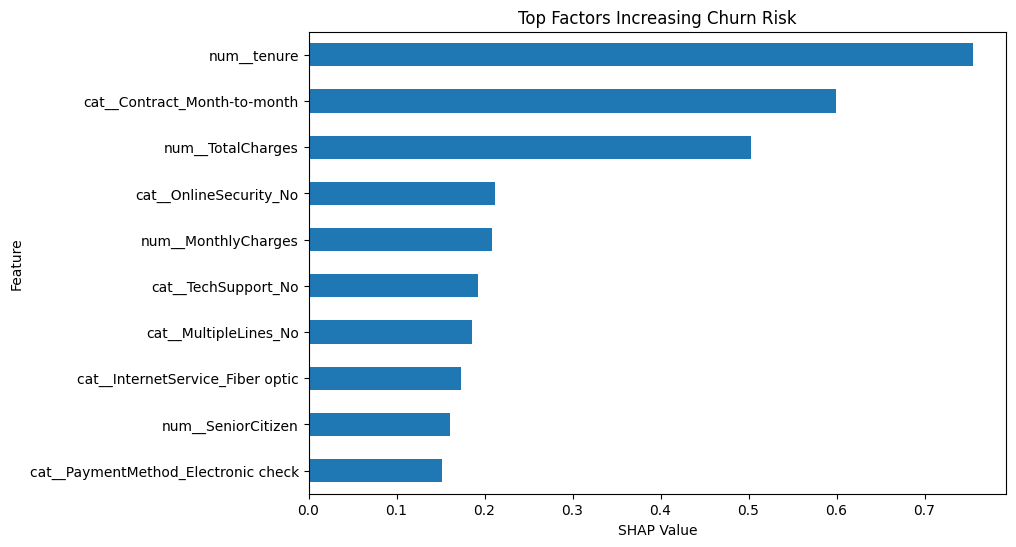

In [ ]:
top_reasons.head(10).sort_values(
    "SHAP_Value"
).plot(
    x="Feature",
    y="SHAP_Value",
    kind="barh",
    figsize=(9, 6),
    legend=False
)

plt.title("Top Factors Increasing Churn Risk")
plt.xlabel("SHAP Value")
plt.ylabel("Feature")

plt.show()

>Visualized the strongest positive SHAP contributions to clearly communicate the main factors driving the selected customer's churn risk.

>Prepared to transform model predictions and SHAP explanations into structured customer profiles that will serve as input for the AI-powered retention recommendation engine.


##Step 8.1 - Customer Risk Profile

###Step 8.1 - Create Customer Risk Profile
####8.1.1 - Get the Selected Customer's Information

In [ ]:
customer_id = high_risk_customer["customerID"]

customer_data = df[
    df["customerID"] == customer_id
].iloc[0]

print("Customer ID:", customer_id)

Customer ID: 5178-LMXOP


>Retrieved the original customer information for the highest-risk customer selected for the AI recommendation workflow.

####8.1.2 — Get Churn Prediction Information

In [ ]:
churn_probability = high_risk_customer["Churn_Probability_Pct"]
risk_level = high_risk_customer["Risk_Level"]

print("Churn Probability:", churn_probability, "%")
print("Risk Level:", risk_level)

Churn Probability: 93.75 %
Risk Level: High


>Retrieved the model-generated churn probability and risk category for the selected customer.

####8.1.3 — Extract Top SHAP Reasons

In [ ]:
top_shap_reasons = top_reasons.head(5)["Feature"].tolist()

top_shap_reasons

['num__tenure',
 'cat__Contract_Month-to-month',
 'num__TotalCharges',
 'cat__OnlineSecurity_No',
 'num__MonthlyCharges']

>Extracted the five strongest positive SHAP contributors to identify the main factors increasing the customer's churn risk.

###8.1.4 — Create the Customer Profile

In [ ]:
customer_profile = {
    "customer_id": customer_id,
    "churn_probability": churn_probability,
    "risk_level": risk_level,

    "contract": customer_data["Contract"],
    "tenure_months": customer_data["tenure"],
    "monthly_charges": customer_data["MonthlyCharges"],
    "total_charges": customer_data["TotalCharges"],
    "internet_service": customer_data["InternetService"],
    "payment_method": customer_data["PaymentMethod"],

    "top_shap_reasons": top_shap_reasons
}

customer_profile

{'customer_id': '5178-LMXOP',
 'churn_probability': np.float32(93.75),
 'risk_level': 'High',
 'contract': 'Month-to-month',
 'tenure_months': np.int64(1),
 'monthly_charges': np.float64(95.1),
 'total_charges': np.float64(95.1),
 'internet_service': 'Fiber optic',
 'payment_method': 'Electronic check',
 'top_shap_reasons': ['num__tenure',
  'cat__Contract_Month-to-month',
  'num__TotalCharges',
  'cat__OnlineSecurity_No',
  'num__MonthlyCharges']}

>Created a structured customer risk profile combining customer attributes, churn probability, risk level, and SHAP-based churn drivers.

####8.1.5 — Display the Profile Clearly

In [ ]:
import json

print(json.dumps(customer_profile, indent=4, default=str))

{
    "customer_id": "5178-LMXOP",
    "churn_probability": "93.75",
    "risk_level": "High",
    "contract": "Month-to-month",
    "tenure_months": "1",
    "monthly_charges": 95.1,
    "total_charges": 95.1,
    "internet_service": "Fiber optic",
    "payment_method": "Electronic check",
    "top_shap_reasons": [
        "num__tenure",
        "cat__Contract_Month-to-month",
        "num__TotalCharges",
        "cat__OnlineSecurity_No",
        "num__MonthlyCharges"
    ]
}


>Converted the customer's prediction, behavioral attributes, and SHAP explanations into a readable structured profile that can be passed to an LLM.

###Step 8.2 — Build the AI Prompt Template

####8.2.1 — Create the Prompt

In [ ]:
prompt = f"""
You are a customer retention strategist.

Analyze the following customer risk profile and provide a practical retention strategy.

Customer ID: {customer_profile['customer_id']}
Churn Probability: {customer_profile['churn_probability']}%
Risk Level: {customer_profile['risk_level']}

Customer Details:
- Contract: {customer_profile['contract']}
- Tenure: {customer_profile['tenure_months']} months
- Monthly Charges: {customer_profile['monthly_charges']}
- Total Charges: {customer_profile['total_charges']}
- Internet Service: {customer_profile['internet_service']}
- Payment Method: {customer_profile['payment_method']}

Main Factors Identified by SHAP:
{customer_profile['top_shap_reasons']}

Based on the information above:

1. Explain briefly why this customer may be at risk.
2. Provide 2-3 practical retention actions.
3. Keep the recommendations realistic and business-focused.
4. Do not invent customer information that is not provided.

Return the response in this format:

Risk Summary:
<short explanation>

Retention Actions:
1. <action>
2. <action>
3. <action>
"""

>Created a structured prompt that provides the LLM with the customer's churn risk, profile, and SHAP-based reasons to generate evidence-based retention strategies.

####8.2.2 — Inspect the Prompt

In [ ]:
print(prompt)


You are a customer retention strategist.

Analyze the following customer risk profile and provide a practical retention strategy.

Customer ID: 5178-LMXOP
Churn Probability: 93.75%
Risk Level: High

Customer Details:
- Contract: Month-to-month
- Tenure: 1 months
- Monthly Charges: 95.1
- Total Charges: 95.1
- Internet Service: Fiber optic
- Payment Method: Electronic check

Main Factors Identified by SHAP:
['num__tenure', 'cat__Contract_Month-to-month', 'num__TotalCharges', 'cat__OnlineSecurity_No', 'num__MonthlyCharges']

Based on the information above:

1. Explain briefly why this customer may be at risk.
2. Provide 2-3 practical retention actions.
3. Keep the recommendations realistic and business-focused.
4. Do not invent customer information that is not provided.

Return the response in this format:

Risk Summary:
<short explanation>

Retention Actions:
1. <action>
2. <action>
3. <action>



>Reviewed the generated prompt to verify that the LLM receives relevant customer information and model-derived churn drivers.

###8.3.1 — Install Gemini SDK

In [ ]:
!pip install -q -U google-genai

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.5/56.5 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 16.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 259.1/259.1 kB 11.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires google-auth==2.49.0, but you have google-auth 2.56.3 which is incompatible.


In [ ]:
import google
from google import genai

print("Google GenAI SDK imported successfully!")

Google GenAI SDK imported successfully!


###8.3.3 — Add Your Gemini API Key

In [ ]:
import getpass

api_key = getpass.getpass("Enter your Gemini API key: ")

Enter your Gemini API key: ··········


###8.3.4 — Create the Gemini Client

In [ ]:
client = genai.Client(api_key=api_key)   #Initialized the Gemini API client using the authenticated API key.

###8.3.5 — Send Our Prompt to Gemini

In [ ]:
response = client.models.generate_content(
    model="gemini-3.5-flash",
    contents=prompt
)

print(response.text)

Risk Summary:
This customer is in their critical first month of service (1-month tenure) on a high-cost Fiber optic plan ($95.10) with no contract commitment (Month-to-month). They are highly vulnerable to immediate churn due to "sticker shock" from high monthly charges, a lack of protective features (No Online Security) that would otherwise increase product stickiness, and a high-friction manual payment method (Electronic check).

Retention Actions:
1. **Contract Transition Incentive:** Reach out to the customer to offer a monthly discount (e.g., $10-$15 off) on their Fiber optic service if they transition from their current Month-to-month plan to a stable 12-month contract, addressing the high monthly charges while securing commitment.
2. **Value-Add Security Bundle:** Offer 3 to 6 months of complimentary Online Security service. Adding this feature addresses the security gap identified by SHAP, increases the perceived value of their high-speed Fiber connection, and embeds the custom

>Sent the structured customer risk profile and SHAP-based churn reasons to Gemini to generate a personalized retention strategy.
>Successfully integrated Gemini with the churn prediction system to generate personalized, evidence-based retention strategies using customer risk information and SHAP explanations.

###8.3.6 — Create the Final AI Recommendation

In [ ]:
ai_recommendation = response.text

print("AI Retention Recommendation:")
print(ai_recommendation)

AI Retention Recommendation:
Risk Summary:
This customer is in their critical first month of service (1-month tenure) on a high-cost Fiber optic plan ($95.10) with no contract commitment (Month-to-month). They are highly vulnerable to immediate churn due to "sticker shock" from high monthly charges, a lack of protective features (No Online Security) that would otherwise increase product stickiness, and a high-friction manual payment method (Electronic check).

Retention Actions:
1. **Contract Transition Incentive:** Reach out to the customer to offer a monthly discount (e.g., $10-$15 off) on their Fiber optic service if they transition from their current Month-to-month plan to a stable 12-month contract, addressing the high monthly charges while securing commitment.
2. **Value-Add Security Bundle:** Offer 3 to 6 months of complimentary Online Security service. Adding this feature addresses the security gap identified by SHAP, increases the perceived value of their high-speed Fiber conn

>Stored the LLM-generated retention strategy so it can be incorporated into the final churn intelligence output.

##Step 8.4 — Create the Final Customer Intelligence Output

###Step 8.4.1 — Create Final Output

In [ ]:
final_customer_intelligence = {
    "Customer ID": customer_profile["customer_id"],
    "Churn Probability": f"{customer_profile['churn_probability']}%",
    "Risk Level": customer_profile["risk_level"],
    "Main Churn Drivers": customer_profile["top_shap_reasons"],
    "AI Retention Strategy": ai_recommendation
}

final_customer_intelligence

{'Customer ID': '5178-LMXOP',
 'Churn Probability': '93.75%',
 'Risk Level': 'High',
 'Main Churn Drivers': ['num__tenure',
  'cat__Contract_Month-to-month',
  'num__TotalCharges',
  'cat__OnlineSecurity_No',
  'num__MonthlyCharges'],
 'AI Retention Strategy': 'Risk Summary:\nThis customer is in their critical first month of service (1-month tenure) on a high-cost Fiber optic plan ($95.10) with no contract commitment (Month-to-month). They are highly vulnerable to immediate churn due to "sticker shock" from high monthly charges, a lack of protective features (No Online Security) that would otherwise increase product stickiness, and a high-friction manual payment method (Electronic check).\n\nRetention Actions:\n1. **Contract Transition Incentive:** Reach out to the customer to offer a monthly discount (e.g., $10-$15 off) on their Fiber optic service if they transition from their current Month-to-month plan to a stable 12-month contract, addressing the high monthly charges while securin

>Combined the model prediction, SHAP-based churn drivers, and Gemini recommendation into a single customer churn intelligence output.

In [ ]:
print("=" * 60)
print("AI-POWERED CUSTOMER CHURN INTELLIGENCE")
print("=" * 60)

print(f"\nCustomer ID: {final_customer_intelligence['Customer ID']}")
print(f"Churn Probability: {final_customer_intelligence['Churn Probability']}")
print(f"Risk Level: {final_customer_intelligence['Risk Level']}")

print("\nMain Churn Drivers:")

for i, reason in enumerate(
    final_customer_intelligence["Main Churn Drivers"],
    1
):
    print(f"{i}. {reason}")

print("\nAI Retention Strategy:")
print(final_customer_intelligence["AI Retention Strategy"])

AI-POWERED CUSTOMER CHURN INTELLIGENCE

Customer ID: 5178-LMXOP
Churn Probability: 93.75%
Risk Level: High

Main Churn Drivers:
1. num__tenure
2. cat__Contract_Month-to-month
3. num__TotalCharges
4. cat__OnlineSecurity_No
5. num__MonthlyCharges

AI Retention Strategy:
Risk Summary:
This customer is in their critical first month of service (1-month tenure) on a high-cost Fiber optic plan ($95.10) with no contract commitment (Month-to-month). They are highly vulnerable to immediate churn due to "sticker shock" from high monthly charges, a lack of protective features (No Online Security) that would otherwise increase product stickiness, and a high-friction manual payment method (Electronic check).

Retention Actions:
1. **Contract Transition Incentive:** Reach out to the customer to offer a monthly discount (e.g., $10-$15 off) on their Fiber optic service if they transition from their current Month-to-month plan to a stable 12-month contract, addressing the high monthly charges while secu

>Created the final customer-level intelligence report combining churn probability, risk level, key churn drivers, and AI-generated retention actions.

##Step 8.5 — Reusable AI Recommendation Engine
###8.5.1 — Create the Function

In [ ]:
def generate_retention_strategy(customer_id):

    # Check whether customer exists
    if customer_id not in prediction_df["customerID"].values:
        return f"Customer ID {customer_id} was not found."

    # Get customer's prediction record
    customer_row = prediction_df[
        prediction_df["customerID"] == customer_id
    ].iloc[0]

    # Get original customer data
    customer_data = df[
        df["customerID"] == customer_id
    ].iloc[0]

    # Get position of customer in X_test
    customer_index = customer_row.name
    customer_position = X_test.index.get_loc(customer_index)

    # Get SHAP values for this customer
    customer_shap = shap_values[customer_position]

    # Create SHAP explanation
    customer_explanation = pd.DataFrame({
        "Feature": feature_names,
        "SHAP_Value": customer_shap
    })

    # Keep only factors increasing churn risk
    top_reasons = (
        customer_explanation[
            customer_explanation["SHAP_Value"] > 0
        ]
        .sort_values("SHAP_Value", ascending=False)
        .head(5)
    )

    # Create customer profile
    customer_profile = {
        "customer_id": customer_id,
        "churn_probability": customer_row["Churn_Probability_Pct"],
        "risk_level": customer_row["Risk_Level"],
        "contract": customer_data["Contract"],
        "tenure_months": customer_data["tenure"],
        "monthly_charges": customer_data["MonthlyCharges"],
        "total_charges": customer_data["TotalCharges"],
        "internet_service": customer_data["InternetService"],
        "payment_method": customer_data["PaymentMethod"],
        "top_shap_reasons": top_reasons["Feature"].tolist()
    }

    # Create LLM prompt
    prompt = f"""
You are a customer retention strategist.

Analyze this customer's churn risk and create a practical,
personalized retention strategy.

Customer ID: {customer_profile['customer_id']}
Churn Probability: {customer_profile['churn_probability']}%
Risk Level: {customer_profile['risk_level']}

Customer Details:
- Contract: {customer_profile['contract']}
- Tenure: {customer_profile['tenure_months']} months
- Monthly Charges: {customer_profile['monthly_charges']}
- Total Charges: {customer_profile['total_charges']}
- Internet Service: {customer_profile['internet_service']}
- Payment Method: {customer_profile['payment_method']}

Main factors identified by SHAP:
{customer_profile['top_shap_reasons']}

Provide:
1. A short risk summary.
2. Three practical retention actions.

Do not invent customer information.
Keep the recommendations realistic and business-focused.
"""

    # Send profile to Gemini
    response = client.models.generate_content(
        model="gemini-3-flash-preview",
        contents=prompt
    )

    # Display final result
    print("=" * 65)
    print("AI-POWERED CUSTOMER CHURN INTELLIGENCE")
    print("=" * 65)

    print(f"\nCustomer ID: {customer_id}")
    print(
        f"Churn Probability: "
        f"{customer_row['Churn_Probability_Pct']}%"
    )
    print(f"Risk Level: {customer_row['Risk_Level']}")

    print("\nMain Churn Drivers:")

    for i, reason in enumerate(
        top_reasons["Feature"].tolist(), 1
    ):
        print(f"{i}. {reason}")

    print("\nAI RETENTION STRATEGY:")
    print(response.text)

    return response.text

>Built a reusable AI recommendation function that automatically retrieves a customer's churn risk, SHAP-based drivers, and customer details before generating a personalized retention strategy with Gemini.

###8.5.2 — Test the Engine

In [ ]:
generate_retention_strategy("5178-LMXOP")

AI-POWERED CUSTOMER CHURN INTELLIGENCE

Customer ID: 5178-LMXOP
Churn Probability: 93.75%
Risk Level: High

Main Churn Drivers:
1. num__tenure
2. cat__Contract_Month-to-month
3. num__TotalCharges
4. cat__OnlineSecurity_No
5. num__MonthlyCharges

AI RETENTION STRATEGY:
As a customer retention strategist, I have analyzed the profile for Customer 5178-LMXOP. With a churn probability of **93.75%**, this customer is in the "critical danger zone." They are a brand-new user who has likely experienced immediate buyer’s remorse or a poor onboarding experience.

### 1. Risk Summary
The primary driver of risk is **initial cost vs. commitment.** At $95.10/month, the customer is paying a premium for Fiber optic service but has no contractual tie to the company (Month-to-month). Because tenure is only 1 month, the customer has not yet formed a habit or realized the long-term value of the service. Furthermore, the lack of **Online Security** makes the service feel like a "utility" rather than a "prot

'As a customer retention strategist, I have analyzed the profile for Customer 5178-LMXOP. With a churn probability of **93.75%**, this customer is in the "critical danger zone." They are a brand-new user who has likely experienced immediate buyer’s remorse or a poor onboarding experience.\n\n### 1. Risk Summary\nThe primary driver of risk is **initial cost vs. commitment.** At $95.10/month, the customer is paying a premium for Fiber optic service but has no contractual tie to the company (Month-to-month). Because tenure is only 1 month, the customer has not yet formed a habit or realized the long-term value of the service. Furthermore, the lack of **Online Security** makes the service feel like a "utility" rather than a "protected experience," making it easier for them to switch to a competitor offering a promotional "first-year" rate.\n\n---\n\n### 2. Practical Retention Actions\n\n**Action 1: The "First Anniversary" Contract Conversion**\n*   **The Move:** Offer a significant monthly

###8.5.3 — Test Another Customer

In [ ]:
prediction_df["customerID"].iloc[10]

'5804-HYIEZ'

In [ ]:
generate_retention_strategy("5804-HYIEZ")

AI-POWERED CUSTOMER CHURN INTELLIGENCE

Customer ID: 5804-HYIEZ
Churn Probability: 41.7400016784668%
Risk Level: Medium

Main Churn Drivers:
1. num__MonthlyCharges
2. cat__Contract_Month-to-month
3. cat__InternetService_Fiber optic
4. cat__gender_Female
5. cat__PaymentMethod_Electronic check

AI RETENTION STRATEGY:
### 1. Risk Summary
Customer 5804-HYIEZ is a high-value, long-term loyalist (70 months) currently at a **Medium Churn Risk (41.74%)**. While her tenure suggests strong brand loyalty, she is currently in a precarious "at-will" state due to her **month-to-month contract** and high **monthly charges ($106.05)**. 

The primary drivers of risk are the lack of structural lock-in and a premium price point for Fiber optic service. Additionally, her use of **electronic checks**—a manual payment method—creates a monthly "pain point" where she must actively decide to pay her high bill, increasing the likelihood of price shopping. Losing a customer with a total lifetime value (LTV) of o

'### 1. Risk Summary\nCustomer 5804-HYIEZ is a high-value, long-term loyalist (70 months) currently at a **Medium Churn Risk (41.74%)**. While her tenure suggests strong brand loyalty, she is currently in a precarious "at-will" state due to her **month-to-month contract** and high **monthly charges ($106.05)**. \n\nThe primary drivers of risk are the lack of structural lock-in and a premium price point for Fiber optic service. Additionally, her use of **electronic checks**—a manual payment method—creates a monthly "pain point" where she must actively decide to pay her high bill, increasing the likelihood of price shopping. Losing a customer with a total lifetime value (LTV) of over $7,500 would be a significant loss for the business.\n\n---\n\n### 2. Practical Retention Actions\n\n**Action 1: High-Value Loyalty Migration (Contract Conversion)**\n*   **Strategy:** Move the customer from a month-to-month plan to a 1-year or 2-year agreement.\n*   **Execution:** Proactively reach out to a

>Tested the recommendation engine with different customer IDs to confirm that the system dynamically generates customer-specific churn explanations and retention strategies.

In [ ]:
# ============================================================
# STEP 9 — FINAL AI CUSTOMER CHURN INTELLIGENCE DATASET
# 7,043 CUSTOMERS + 10 AI RECOMMENDATIONS
# ============================================================

import pandas as pd
import numpy as np
from google.colab import files

print("Creating final customer intelligence dataset...")

# ------------------------------------------------------------
# 1. Start with the existing prediction results
# ------------------------------------------------------------

final_df = df.copy()

# Use the probabilities already generated by the model
# If prediction_df contains predictions for the test set only,
# we use the model to predict the complete dataset here.

X_full = df.drop(columns=["customerID", "Churn"])
X_full_processed = preprocessor.transform(X_full)

full_probability = best_model.predict_proba(
    X_full_processed
)[:, 1]

final_df["Churn_Probability"] = (
    full_probability * 100
).round(2)


# ------------------------------------------------------------
# 2. Assign Risk Level
# ------------------------------------------------------------

def get_risk(probability):
    if probability < 30:
        return "Low"
    elif probability < 60:
        return "Medium"
    else:
        return "High"

final_df["Risk_Level"] = [
    get_risk(p)
    for p in final_df["Churn_Probability"]
]


# ------------------------------------------------------------
# 3. Calculate SHAP values
# ------------------------------------------------------------

print("Calculating SHAP explanations...")

full_shap_values = explainer.shap_values(
    X_full_processed
)


# ------------------------------------------------------------
# 4. Convert technical SHAP names into readable names
# ------------------------------------------------------------

def clean_feature_name(feature):

    # Remove preprocessing prefixes
    feature = feature.replace("num__", "")
    feature = feature.replace("cat__", "")

    # Replace encoded category names
    feature = feature.replace("_Month-to-month", ": Month-to-month")
    feature = feature.replace("_One year", ": One year")
    feature = feature.replace("_Two year", ": Two year")

    feature = feature.replace("_Yes", ": Yes")
    feature = feature.replace("_No", ": No")

    feature = feature.replace("_Electronic check", ": Electronic check")
    feature = feature.replace("_Mailed check", ": Mailed check")
    feature = feature.replace("_Credit card (automatic)", ": Credit card (automatic)")
    feature = feature.replace("_Bank transfer (automatic)", ": Bank transfer (automatic)")

    feature = feature.replace("_Fiber optic", ": Fiber optic")
    feature = feature.replace("_DSL", ": DSL")
    feature = feature.replace("_No internet service", ": No internet service")

    # General formatting
    feature = feature.replace("_", " ")

    # Business-friendly names
    replacements = {
        "tenure": "Customer tenure",
        "MonthlyCharges": "Monthly charges",
        "TotalCharges": "Total charges",
        "SeniorCitizen": "Senior citizen",
        "OnlineSecurity": "Online security",
        "OnlineBackup": "Online backup",
        "DeviceProtection": "Device protection",
        "TechSupport": "Technical support",
        "PaymentMethod": "Payment method",
        "InternetService": "Internet service",
        "Contract": "Contract type",
        "PaperlessBilling": "Paperless billing",
        "StreamingTV": "Streaming TV",
        "StreamingMovies": "Streaming movies",
        "Partner": "Partner",
        "Dependents": "Dependents",
        "MultipleLines": "Multiple lines",
        "PhoneService": "Phone service"
    }

    for old, new in replacements.items():
        feature = feature.replace(old, new)

    return feature.strip()


# ------------------------------------------------------------
# 5. Create readable SHAP reason columns
# ------------------------------------------------------------

for n in range(1, 6):
    final_df[f"SHAP_Reason_{n}"] = None


for i in range(len(final_df)):

    explanation = pd.DataFrame({
        "Feature": feature_names,
        "SHAP_Value": full_shap_values[i]
    })

    # Only factors increasing churn probability
    reasons = (
        explanation[
            explanation["SHAP_Value"] > 0
        ]
        .sort_values(
            "SHAP_Value",
            ascending=False
        )
        .head(5)
    )

    readable_reasons = [
        clean_feature_name(feature)
        for feature in reasons["Feature"]
    ]

    for n, reason in enumerate(
        readable_reasons,
        start=1
    ):
        final_df.loc[
            final_df.index[i],
            f"SHAP_Reason_{n}"
        ] = reason


# ------------------------------------------------------------
# 6. Create AI Recommendation column
# ------------------------------------------------------------

final_df["AI_Retention_Strategy"] = None


# ------------------------------------------------------------
# 7. Select 5 High + 5 Medium Risk Customers
# ------------------------------------------------------------

high_risk = (
    final_df[
        final_df["Risk_Level"] == "High"
    ]
    .sort_values(
        "Churn_Probability",
        ascending=False
    )
    .head(5)
)

medium_risk = (
    final_df[
        final_df["Risk_Level"] == "Medium"
    ]
    .sort_values(
        "Churn_Probability",
        ascending=False
    )
    .head(5)
)

sample_customers = pd.concat([
    high_risk,
    medium_risk
])

print("\n" + "=" * 60)
print("CUSTOMERS SELECTED FOR AI RECOMMENDATIONS")
print("=" * 60)

display(
    sample_customers[
        [
            "customerID",
            "Churn_Probability",
            "Risk_Level",
            "SHAP_Reason_1",
            "SHAP_Reason_2",
            "SHAP_Reason_3"
        ]
    ]
)


# ------------------------------------------------------------
# 8. Generate Gemini Recommendations
# ------------------------------------------------------------

print("\nGenerating Gemini recommendations...\n")

for number, (index, customer) in enumerate(
    sample_customers.iterrows(),
    start=1
):

    reasons = [
        customer[f"SHAP_Reason_{n}"]
        for n in range(1, 6)
        if pd.notna(
            customer[f"SHAP_Reason_{n}"]
        )
    ]

    reasons_text = "\n".join(
        f"- {reason}"
        for reason in reasons
    )

    prompt = f"""
You are a customer retention strategist.

Create a concise, evidence-based retention strategy
for this customer.

Customer ID: {customer["customerID"]}

Churn Probability:
{customer["Churn_Probability"]}%

Risk Level:
{customer["Risk_Level"]}

Customer Information:
- Tenure: {customer["tenure"]} months
- Contract: {customer["Contract"]}
- Monthly Charges: {customer["MonthlyCharges"]}
- Total Charges: {customer["TotalCharges"]}
- Internet Service: {customer["InternetService"]}
- Payment Method: {customer["PaymentMethod"]}
- Online Security: {customer["OnlineSecurity"]}
- Tech Support: {customer["TechSupport"]}

Top SHAP factors increasing churn risk:
{reasons_text}

IMPORTANT RULES:

1. Use only the information provided.
2. Do not invent customer behavior.
3. Do not claim that a discount or special offer already exists.
4. You may suggest an offer as a possible business action,
   but clearly present it as a recommendation.
5. Do not say that a factor is definitely causing churn.
6. Keep the strategy practical and business-focused.

Return exactly:

Risk Summary:
<2-3 concise sentences>

Retention Actions:
1. <action>
2. <action>
3. <action>
"""

    print(
        f"Processing {number}/10: "
        f"{customer['customerID']}"
    )

    try:

        response = client.models.generate_content(
            model="gemini-3-flash-preview",
            contents=prompt
        )

        recommendation = response.text.strip()

        # IMPORTANT: write directly to final_df
        final_df.loc[
            index,
            "AI_Retention_Strategy"
        ] = recommendation

        print("✓ Recommendation generated")

    except Exception as e:

        print("✗ Gemini error:")
        print(e)

        final_df.loc[
            index,
            "AI_Retention_Strategy"
        ] = "AI recommendation could not be generated."


# ------------------------------------------------------------
# 9. Arrange final columns
# ------------------------------------------------------------

desired_columns = [
    "customerID",
    "gender",
    "SeniorCitizen",
    "Partner",
    "Dependents",
    "tenure",
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "Contract",
    "PaperlessBilling",
    "PaymentMethod",
    "MonthlyCharges",
    "TotalCharges",
    "Churn",
    "Churn_Probability",
    "Risk_Level",
    "SHAP_Reason_1",
    "SHAP_Reason_2",
    "SHAP_Reason_3",
    "SHAP_Reason_4",
    "SHAP_Reason_5",
    "AI_Retention_Strategy"
]

desired_columns = [
    col
    for col in desired_columns
    if col in final_df.columns
]

final_df = final_df[desired_columns]


# ------------------------------------------------------------
# 10. Export CSV
# ------------------------------------------------------------

output_file = "AI_Customer_Churn_Intelligence_FINAL.csv"

final_df.to_csv(
    output_file,
    index=False
)


# ------------------------------------------------------------
# 11. Validation
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("FINAL DATASET CREATED")
print("=" * 60)

print(f"\nTotal customers: {len(final_df)}")

print(
    "High-risk customers:",
    (final_df["Risk_Level"] == "High").sum()
)

print(
    "Medium-risk customers:",
    (final_df["Risk_Level"] == "Medium").sum()
)

print(
    "AI recommendations generated:",
    final_df[
        "AI_Retention_Strategy"
    ].notna().sum()
)

print("\nAI Recommendation Customers:")

display(
    final_df[
        final_df["AI_Retention_Strategy"].notna()
    ][
        [
            "customerID",
            "Churn_Probability",
            "Risk_Level",
            "SHAP_Reason_1",
            "SHAP_Reason_2",
            "SHAP_Reason_3",
            "AI_Retention_Strategy"
        ]
    ]
)


# ------------------------------------------------------------
# 12. Download
# ------------------------------------------------------------

files.download(output_file)

print("\n✓ File downloaded:")
print(output_file)

Creating final customer intelligence dataset...
Calculating SHAP explanations...

CUSTOMERS SELECTED FOR AI RECOMMENDATIONS


,customerID,Churn_Probability,Risk_Level,SHAP_Reason_1,SHAP_Reason_2,SHAP_Reason_3
4800,9300-AGZNL,94.959999,High,Customer tenure,Contract type: Month-to-month,Total charges
6482,5419-JPRRN,94.510002,High,Customer tenure,Contract type: Month-to-month,Total charges
1976,9497-QCMMS,94.480003,High,Customer tenure,Contract type: Month-to-month,Total charges
2208,7216-EWTRS,94.010002,High,Customer tenure,Contract type: Month-to-month,Total charges
3209,8149-RSOUN,93.959999,High,Customer tenure,Contract type: Month-to-month,Total charges
6001,4367-NHWMM,59.950001,Medium,Customer tenure,Contract type: Month-to-month,Total charges
3838,7714-YXSMB,59.930000,Medium,Contract type: Month-to-month,Monthly charges,Internet service: Fiber optic
882,3908-BLSYF,59.889999,Medium,Contract type: Month-to-month,Customer tenure,Online security: No
2873,0148-DCDOS,59.810001,Medium,Contract type: Month-to-month,Internet service: Fiber optic,Technical support: No
5634,2320-JRSDE,59.750000,Medium,Customer tenure,Total charges,Contract type: Month-to-month



Generating Gemini recommendations...

Processing 1/10: 9300-AGZNL
✓ Recommendation generated
Processing 2/10: 5419-JPRRN
✓ Recommendation generated
Processing 3/10: 9497-QCMMS
✓ Recommendation generated
Processing 4/10: 7216-EWTRS
✓ Recommendation generated
Processing 5/10: 8149-RSOUN
✗ Gemini error:
429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. \n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 5, model: gemini-3-flash\nPlease retry in 1.523630306s.', 'status': 'RESOURCE_EXHAUSTED', 'details': [{'@type': 'type.googleapis.com/google.rpc.Help', 'links': [{'description': 'Learn more about Gemini API quotas', 'url': 'https://ai.google.dev/gemini-api/docs/rate-limits'}]}, {'@type': 

,customerID,Churn_Probability,Risk_Level,SHAP_Reason_1,SHAP_Reason_2,SHAP_Reason_3,AI_Retention_Strategy
882,3908-BLSYF,59.889999,Medium,Contract type: Month-to-month,Customer tenure,Online security: No,AI recommendation could not be generated.
1976,9497-QCMMS,94.480003,High,Customer tenure,Contract type: Month-to-month,Total charges,Risk Summary:\nThis new customer is at critica...
2208,7216-EWTRS,94.010002,High,Customer tenure,Contract type: Month-to-month,Total charges,Risk Summary:\nThis customer is at critical ri...
2873,0148-DCDOS,59.810001,Medium,Contract type: Month-to-month,Internet service: Fiber optic,Technical support: No,AI recommendation could not be generated.
3209,8149-RSOUN,93.959999,High,Customer tenure,Contract type: Month-to-month,Total charges,AI recommendation could not be generated.
3838,7714-YXSMB,59.930000,Medium,Contract type: Month-to-month,Monthly charges,Internet service: Fiber optic,AI recommendation could not be generated.
4800,9300-AGZNL,94.959999,High,Customer tenure,Contract type: Month-to-month,Total charges,Risk Summary:\nThis new customer is at critica...
5634,2320-JRSDE,59.750000,Medium,Customer tenure,Total charges,Contract type: Month-to-month,AI recommendation could not be generated.
6001,4367-NHWMM,59.950001,Medium,Customer tenure,Contract type: Month-to-month,Total charges,AI recommendation could not be generated.
6482,5419-JPRRN,94.510002,High,Customer tenure,Contract type: Month-to-month,Total charges,Risk Summary:\nThis customer is at critical ri...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


✓ File downloaded:
AI_Customer_Churn_Intelligence_FINAL.csv


In [ ]:
# ============================================================
# EXPORT TRAINED CHURN MODEL FOR LOCAL DEPLOYMENT
# ============================================================

import joblib
import os
import shutil
from google.colab import files

# ------------------------------------------------------------
# 1. Create deployment folder
# ------------------------------------------------------------

deployment_folder = "churn_model_deployment"

os.makedirs(deployment_folder, exist_ok=True)

# ------------------------------------------------------------
# 2. Save trained model
# ------------------------------------------------------------

joblib.dump(
    best_model,
    f"{deployment_folder}/churn_model.pkl"
)

# ------------------------------------------------------------
# 3. Save preprocessing pipeline
# ------------------------------------------------------------

joblib.dump(
    preprocessor,
    f"{deployment_folder}/preprocessor.pkl"
)

# ------------------------------------------------------------
# 4. Save feature names
# ------------------------------------------------------------

joblib.dump(
    feature_names,
    f"{deployment_folder}/feature_names.pkl"
)

# ------------------------------------------------------------
# 5. Save SHAP explainer
# ------------------------------------------------------------

joblib.dump(
    explainer,
    f"{deployment_folder}/shap_explainer.pkl"
)

# ------------------------------------------------------------
# 6. Save model metadata
# ------------------------------------------------------------

metadata = {
    "model": "XGBoost",
    "model_file": "churn_model.pkl",
    "preprocessor_file": "preprocessor.pkl",
    "shap_explainer_file": "shap_explainer.pkl",
    "feature_names_file": "feature_names.pkl",
    "risk_thresholds": {
        "low": "< 30%",
        "medium": "30% - 59.99%",
        "high": ">= 60%"
    }
}

joblib.dump(
    metadata,
    f"{deployment_folder}/metadata.pkl"
)

# ------------------------------------------------------------
# 7. Create ZIP file
# ------------------------------------------------------------

zip_file = shutil.make_archive(
    "churn_model_deployment",
    "zip",
    deployment_folder
)

# ------------------------------------------------------------
# 8. Check files
# ------------------------------------------------------------

print("=" * 60)
print("MODEL DEPLOYMENT PACKAGE CREATED")
print("=" * 60)

print("\nFiles included:")

for file in os.listdir(deployment_folder):
    print("✓", file)

print("\nZIP file:", zip_file)

# ------------------------------------------------------------
# 9. Download ZIP
# ------------------------------------------------------------

files.download(zip_file)

MODEL DEPLOYMENT PACKAGE CREATED

Files included:
✓ metadata.pkl
✓ preprocessor.pkl
✓ churn_model.pkl
✓ feature_names.pkl
✓ shap_explainer.pkl

ZIP file: /content/churn_model_deployment.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>